# 04 · Especialização por agente e placar das 3 configurações

**Por que agente e não LoRA:** treinar LoRA de um modelo de 3B exige GPU NVIDIA (CUDA) e centenas de pares revisados. Temos GPU AMD no Windows e 8 dias. O agente roda no mesmo modelo local, é avaliável no mesmo placar e ataca as causas de erro do RAG simples:

| Erro do RAG simples | Passo do agente que corrige |
|---|---|
| Pergunta coloquial busca o trecho errado | Triagem + **reescrita** da consulta com termos oficiais, busca dupla |
| Cita `trecho_id` mal formatado ou inexistente | **Geração restrita**: o JSON Schema só aceita ids recuperados; o sistema preenche `documento` |
| Inventa número/prazo | **Verificação determinística**: todo número da resposta precisa estar no trecho citado |
| Afirma algo que o trecho não diz | **Verificação pelo LLM** + 1 nova tentativa, senão recusa |
| Cola o contexto inteiro na resposta | Remoção de ids e limite de tamanho, com nova tentativa |

Cada decisão fica registrada em `passos` (explicabilidade).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
import pandas as pd
pd.set_option('display.max_colwidth', 120)

In [2]:
from pf_genai import agente, gerador, avaliacao as av
from pf_genai.indice import Indice
idx = Indice.carregar()
print('LLM:', gerador.llm.MODELO, '| limiar:', gerador.LIMIAR, '| verificador bloqueia:', agente.VERIFICADOR_BLOQUEIA)
r = agente.responder('Meu pai tem 62 anos. Ele precisa pagar ônibus? Como faz?', idx)
print(json.dumps(r.resposta.model_dump(), ensure_ascii=False, indent=2))
for p in r.passos: print(' -', p)

LLM: qwen2.5:3b | limiar: 0.86 | verificador bloqueia: True


{
  "resposta": "Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone 156.",
  "fontes": [],
  "confianca": "baixa",
  "nao_consta": true
}
 - triagem: no_escopo=True consulta='gratuidade pessoa idosa 65 anos ônibus'
 - busca: [('lei-10741-transporte-002', 0.9092), ('sptrans-gratuidade-65-mais-003', 0.9073), ('sptrans-gratuidade-65-mais-001', 0.8995), ('sptrans-gratuidade-65-mais-028', 0.8966)]
 - tentativa 1: verificador recusou (Seu pai precisa apresentar um documento pessoal que comprove sua idade para desembarcar, não há custo para o Bilhete Único Especial Pessoa Idosa.)
 - tentativa 2: verificador recusou (Seu pai precisa apresentar um documento pessoal que comprove sua idade para desembarcar, não há custo para o Bilhete Único Especial Pessoa Idosa.)
 - duas tentativas sem fundamentação: recusa com confiança baixa


## Condições equivalentes
As 3 configurações usam o **mesmo** modelo (qwen2.5:3b), temperatura 0, semente 42, o mesmo índice e5-large, o mesmo limiar (0,86) e as mesmas perguntas. Só muda a estratégia. O placar é gerado por `python scripts/rodar_placar.py --conjunto dev|teste` e este notebook **lê** os resultados gravados (rodar de novo aqui poderia gerar uma segunda medição do teste).

**Métricas** (determinísticas, `src/pf_genai/avaliacao.py`):
- **acerto**: respondível com todos os fatos do gabarito, ou "não consta" recusada;
- **recusa correta (não consta)**: % das perguntas sem resposta na base que foram recusadas;
- **alucinação**: respondeu algo errado ou respondeu o que não consta;
- **recusa indevida**: % das respondíveis que foram recusadas;
- **sem fundamentação**: resposta afirmativa sem citação válida ou com número que não está nos trechos citados;
- **precisão das citações**: das citações feitas nas respondíveis, % que são trechos do gabarito; **citações válidas**: % que existem na base;
- recusa é julgada pelo texto que seria **falado**, não só pela flag `nao_consta`.

## Desenvolvimento: histórico de ajustes no DEV
Cada iteração mudou uma coisa e foi medida só no DEV (`avaliacao/historico_dev/`).

In [3]:
hist = []
for f in sorted((RAIZ / 'avaliacao' / 'historico_dev').glob('placar_dev_iter*.csv')):
    d = pd.read_csv(f)
    d = d[d.configuracao == 'agente'].assign(iteracao=f.stem.replace('placar_dev_', ''))
    hist.append(d)
hist = pd.concat(hist).set_index('iteracao')
hist['mudanca'] = ['versão inicial', 'checagem de números ignora ids; verificador menos rígido; sem veto da triagem',
                   'verificador só rebaixa a confiança', 'exige evidência literal copiada do trecho', 'FINAL: volta a bloquear pelo verificador'][:len(hist)]
hist[['mudanca', 'acerto_total_%', 'recusa_correta_nao_consta_%', 'alucinacao_%', 'recusa_indevida_%', 'sem_fundamentacao_%', 'precisao_citacoes_%']]

,mudanca,acerto_total_%,recusa_correta_nao_consta_%,alucinacao_%,recusa_indevida_%,sem_fundamentacao_%,precisao_citacoes_%
iteracao,,,,,,,
iter1,versão inicial,66.7,100.0,3.3,45.0,0.0,84.6
iter2,checagem de números ignora ids; verificador menos rígido; sem veto da triagem,70.0,100.0,0.0,45.0,0.0,84.6
iter3,verificador só rebaixa a confiança,70.0,70.0,26.7,5.0,0.0,69.6
iter4,exige evidência literal copiada do trecho,60.0,70.0,40.0,0.0,0.0,72.7
iter5_final,FINAL: volta a bloquear pelo verificador,66.7,100.0,6.7,40.0,0.0,66.7


**Escolha no DEV:** o verificador LLM do 3B é pouco discriminativo: aponta "problema" até em respostas certas. Bloquear custa recusas indevidas; não bloquear deixa passar respostas para perguntas que não constam (ex.: inventar o horário de um posto). Para um assistente lido em voz alta para idosos e pessoas com deficiência visual, escolhemos **bloquear**: "não encontrei, ligue 156" é melhor do que uma informação errada.

In [4]:
placar_dev = pd.read_csv(RAIZ / 'avaliacao' / 'placar_dev.csv').set_index('configuracao')
placar_dev

,acerto_total_%,acerto_respondiveis_%,recusa_correta_nao_consta_%,alucinacao_%,recusa_indevida_%,citacao_correta_%,sem_fundamentacao_%,citacoes_validas_%,precisao_citacoes_%,json_valido_%,nao_consta_incoerente_%,latencia_media_s,n
configuracao,,,,,,,,,,,,,
sem_contexto,6.7,5.0,10.0,90.0,5.0,0.0,100.0,0.0,0.0,96.7,90.0,0.84,30
rag,63.3,60.0,70.0,36.7,0.0,85.0,13.0,95.7,81.0,100.0,3.3,1.85,30
agente,66.7,50.0,100.0,6.7,40.0,83.3,0.0,100.0,66.7,100.0,0.0,3.47,30


## Avaliação final no TESTE (rodada uma vez, depois de congelar o agente)

In [5]:
placar = pd.read_csv(RAIZ / 'avaliacao' / 'placar_teste.csv').set_index('configuracao')
cols = ['acerto_total_%', 'acerto_respondiveis_%', 'recusa_correta_nao_consta_%', 'alucinacao_%', 'recusa_indevida_%',
        'sem_fundamentacao_%', 'citacao_correta_%', 'precisao_citacoes_%', 'citacoes_validas_%', 'json_valido_%', 'nao_consta_incoerente_%', 'latencia_media_s']
placar[cols]

,acerto_total_%,acerto_respondiveis_%,recusa_correta_nao_consta_%,alucinacao_%,recusa_indevida_%,sem_fundamentacao_%,citacao_correta_%,precisao_citacoes_%,citacoes_validas_%,json_valido_%,nao_consta_incoerente_%,latencia_media_s
configuracao,,,,,,,,,,,,
sem_contexto,5.0,3.3,10.0,85.0,13.3,100.0,0.0,0.0,0.0,87.5,82.5,0.84
rag,67.5,56.7,100.0,20.0,16.7,4.0,84.0,80.8,96.2,95.0,0.0,1.75
agente,52.5,36.7,100.0,5.0,56.7,0.0,100.0,81.2,100.0,100.0,0.0,2.66


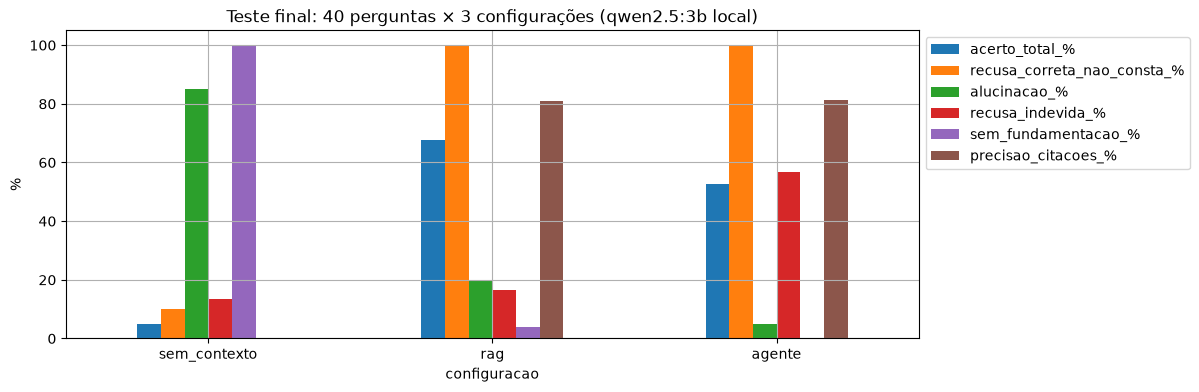

In [6]:
import matplotlib.pyplot as plt
ax = placar[['acerto_total_%', 'recusa_correta_nao_consta_%', 'alucinacao_%', 'recusa_indevida_%', 'sem_fundamentacao_%', 'precisao_citacoes_%']].plot.bar(figsize=(11, 4), rot=0, grid=True)
ax.set_ylabel('%'); ax.set_title('Teste final: 40 perguntas × 3 configurações (qwen2.5:3b local)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.savefig(RAIZ / 'avaliacao' / 'placar_teste.png', dpi=120, bbox_inches='tight')

In [7]:
todas = pd.concat([pd.read_json(RAIZ / 'avaliacao' / f'resultados_teste_{c}.jsonl', lines=True) for c in ['sem_contexto', 'rag', 'agente']])
pd.crosstab(todas['categoria'], todas['configuracao'], values=todas['acerto'], aggfunc='mean').round(2)

configuracao,agente,rag,sem_contexto
categoria,,,
bilhete_tarifa,0.5,0.38,0.00
estudante,0.0,0.50,0.00
idoso_60_64,0.0,0.40,0.00
idoso_65,0.0,0.60,0.00
lei,1.0,1.00,0.25
nao_consta,1.0,1.00,0.10
pcd,0.5,0.67,0.00


## Erros do agente no teste (matéria-prima dos 5 erros reais, ver `avaliacao/erros.md`)

In [8]:
erros = todas[(todas.configuracao == 'agente') & (~todas.acerto)]
erros[['id', 'categoria', 'nao_consta_esperado', 'resposta', 'fontes', 'recuperados', 'passos']]

,id,categoria,nao_consta_esperado,resposta,fontes,recuperados,passos
0,q01,idoso_65,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-gratuidade-65-mais-001, sptrans-gratuidade-65-mais-004, sptrans-gratuidade-65-mais-015, sptrans-gratuidade-...","[triagem: no_escopo=True consulta='pessoa idosa 65 anos cartão', busca: [('sptrans-gratuidade-65-mais-001', 0.8991),..."
1,q02,idoso_60_64,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-gratuidade-60-64-009, sptrans-gratuidade-60-64-001, sptrans-gratuidade-60-64-011, sptrans-gratuidade-60-64-...","[triagem: no_escopo=True consulta='pessoa idosa 60 anos cartão', busca: [('sptrans-gratuidade-60-64-009', 0.8985), (..."
4,q05,bilhete_tarifa,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-bilhete-unico-001, sptrans-bilhete-unico-017, sptrans-bilhete-unico-025, sptrans-tarifas-005]","[triagem: no_escopo=True consulta='tarifa Bilhete Único atual preço', busca: [('sptrans-bilhete-unico-001', 0.8752),..."
7,q08,idoso_65,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-gratuidade-65-mais-012, sptrans-gratuidade-60-64-005, sptrans-gratuidade-65-mais-017, sptrans-gratuidade-65...","[triagem: no_escopo=False consulta='tempo de entrega cartão idoso SPTrans', busca: [('sptrans-gratuidade-65-mais-012..."
9,q10,idoso_60_64,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-gratuidade-60-64-012, sptrans-gratuidade-60-64-001, sptrans-gratuidade-65-mais-003, sptrans-gratuidade-60-6...","[triagem: no_escopo=True consulta='gratuidade pessoa idosa 60 anos', busca: [('sptrans-gratuidade-60-64-012', 0.8966..."
12,q13,pcd,False,"Se estiver desacompanhado, você deve girar a catraca apenas uma vez.",[sptrans-bilhete-pcd-021],"[sptrans-bilhete-pcd-021, sptrans-bilhete-pcd-022, sptrans-bilhete-pcd-001, sptrans-bilhete-pcd-036]","[triagem: no_escopo=True consulta='Bilhete Único Especial integração', busca: [('sptrans-bilhete-pcd-021', 0.8813), ..."
13,q14,estudante,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-bilhete-pcd-036, sptrans-bilhete-estudante-015, sptrans-bilhete-estudante-026, sptrans-bilhete-estudante-007]","[triagem: no_escopo=False consulta='gratuidade pessoa com deficiência ou estudante Pix', busca: [('sptrans-bilhete-p..."
15,q16,idoso_65,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-gratuidade-65-mais-015, sptrans-gratuidade-60-64-021, sptrans-gratuidade-65-mais-022, sptrans-gratuidade-65...","[triagem: no_escopo=False consulta='cartão de idoso emprestado', busca: [('sptrans-gratuidade-65-mais-015', 0.8696),..."
21,q22,idoso_60_64,False,"Não encontrei essa informação nas fontes oficiais que eu conheço. Para ter certeza, ligue para a SPTrans no telefone...",[],"[sptrans-gratuidade-60-64-002, sptrans-gratuidade-60-64-029, sptrans-gratuidade-60-64-013, sptrans-gratuidade-60-64-...","[triagem: no_escopo=True consulta='saldo do Bilhete Único restos gratuidade', busca: [('sptrans-gratuidade-60-64-002..."
22,q23,bilhete_tarifa,False,Ônibus é de graça no domingo de 0h às 23h59.,[sptrans-bilhete-unico-031],"[sptrans-bilhete-unico-031, sptrans-gratuidade-60-64-012, sptrans-tarifas-005, sptrans-gratuidade-60-64-005]","[triagem: no_escopo=True consulta='gratuidade domingo horário último ônibus', busca: [('sptrans-bilhete-unico-031', ..."
